In [1]:
import sys, json, warnings, io, unittest
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import joblib
from src.evaluation import final_evaluation as E, feature_selection as F, nested_tuning as NT, baseline_comparison as B
from src.evaluation.run_feature_selection import load
from src.features import preprocessing as P

pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 120, 'display.max_colwidth', 70)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True); TAB = ROOT / 'reports' / 'tables'
E.run_all()                                                     # no-op when the cache exists
df, X, y, folds = load()
OOF = E.add_matched_segment(pd.read_csv(E.OUT / 'oof_predictions.csv.gz'))
RF = pd.read_csv(E.OUT / 'refit_predictions.csv.gz'); PERM = pd.read_csv(E.OUT / 'grouped_permutation_importance.csv')
META = json.loads((E.OUT / 'run_metadata.json').read_text())
LAB = {'gbr_tuned': 'Gradient Boosting (tuned)', 'enet_tuned': 'ElasticNet (tuned)', 'lasso_fixed': 'Lasso (fixed)'}
COL = {'gbr_tuned': '#d1495b', 'enet_tuned': '#3d5a80', 'lasso_fixed': '#6c757d'}
M = list(LAB)
R0 = OOF[OOF.repeat == E.PRIMARY_REPEAT]
print('out-of-fold table:', OOF.shape, '| houses:', OOF.row.nunique(), '| repeat-0 per-house table:', R0[R0.model == 'gbr_tuned'].shape[0], 'rows per model')

out-of-fold table: (13140, 18) | houses: 1460 | repeat-0 per-house table: 1460 rows per model


In [2]:
cols = ['model', 'Id', 'fold', 'repeat', 'y', 'pred', 'y_log', 'pred_log', 'residual_usd', 'residual_log', 'abs_err_usd', 'sq_err_usd', 'ape', 'segment_pred', 'segment_actual']
display(OOF[cols].head(4).round(4))
print(f'Rows: {len(OOF):,} = 3 models x 1,460 houses x 3 repeats. Each house has ONE prediction per repeat per model, and the three repeat predictions are NOT independent houses.')
print('Conventions: residual = actual - predicted (positive = underprediction); APE = |residual| / actual; predictions are medians (expm1 of the log1p prediction).')
print('Headline metrics: mean of the 15 fold-level metrics. Per-house diagnostics (plots, error tables, largest errors): repeat 0 only = one prediction per house from a genuine 5-fold partition (n = 1,460).')
print('Segment edges (fixed in code, rounded P25 and P90 of the SalePrice distribution): low < $%s <= mid < $%s <= luxury' % tuple(f'{e:,}' for e in E.SEGMENT_EDGES))
print('Predicted-price segment sizes in repeat 0:'); display(R0.groupby(['model', 'segment_pred']).size().unstack().reindex(columns=list(E.SEGMENTS)))

,model,Id,fold,repeat,y,pred,y_log,pred_log,residual_usd,residual_log,abs_err_usd,sq_err_usd,ape,segment_pred,segment_actual
0,enet_tuned,7,0,0,307000.0,277915.7619,12.6346,12.5351,29084.2381,0.0995,29084.2381,8.458929e+08,0.0947,mid,luxury
1,enet_tuned,10,0,0,118000.0,123701.0969,11.6784,11.7256,-5701.0969,-0.0472,5701.0969,3.250251e+07,0.0483,low,low
2,enet_tuned,12,0,0,345000.0,376129.6753,12.7513,12.8377,-31129.6753,-0.0864,31129.6753,9.690567e+08,0.0902,luxury,luxury
3,enet_tuned,20,0,0,139000.0,132578.3483,11.8422,11.7949,6421.6517,0.0473,6421.6517,4.123761e+07,0.0462,mid,mid


Rows: 13,140 = 3 models x 1,460 houses x 3 repeats. Each house has ONE prediction per repeat per model, and the three repeat predictions are NOT independent houses.
Conventions: residual = actual - predicted (positive = underprediction); APE = |residual| / actual; predictions are medians (expm1 of the log1p prediction).
Headline metrics: mean of the 15 fold-level metrics. Per-house diagnostics (plots, error tables, largest errors): repeat 0 only = one prediction per house from a genuine 5-fold partition (n = 1,460).
Segment edges (fixed in code, rounded P25 and P90 of the SalePrice distribution): low < $130,000 <= mid < $280,000 <= luxury
Predicted-price segment sizes in repeat 0:


segment_pred,low,mid,luxury
model,,,
enet_tuned,387,942,131
gbr_tuned,367,954,139
lasso_fixed,383,947,130


In [3]:
FM = E.fold_metrics(OOF)
tab = FM.groupby('model').agg(**{'Log-RMSE mean': ('rmse_log', 'mean'), 'Log-RMSE SD': ('rmse_log', 'std'), 'Log-RMSE min': ('rmse_log', 'min'), 'Log-RMSE max': ('rmse_log', 'max'),
                                 'MAE USD': ('mae', 'mean'), 'RMSE USD': ('rmse_usd', 'mean'), 'RMSE USD SD': ('rmse_usd', 'std'), 'MAPE %': ('mape', 'mean'), 'R2 USD': ('r2_usd', 'mean')}).loc[M]
tab.index = [LAB[m] for m in tab.index]
display(tab.round({'Log-RMSE mean': 4, 'Log-RMSE SD': 4, 'Log-RMSE min': 4, 'Log-RMSE max': 4, 'MAE USD': 0, 'RMSE USD': 0, 'RMSE USD SD': 0, 'MAPE %': 2, 'R2 USD': 3}))
mets = {m: FM[FM.model == m].sort_values('fold').reset_index(drop=True) for m in M}
pt = F.paired_vs_reference(mets, 'gbr_tuned')
print('Paired fold differences vs tuned Gradient Boosting (diff > 0 means the model is WORSE; Nadeau-Bengio corrected interval):')
display(pt.loc[['enet_tuned', 'lasso_fixed'], ['rmse_log', 'diff', 'ci_lo', 'ci_hi', 'folds_better', 'repeats_better', 'verdict', 'mae_diff']].rename(index=LAB).round(4))
rep = FM.groupby(['model', 'repeat']).rmse_log.mean().unstack().loc[M]; rep.index = [LAB[m] for m in rep.index]
print('Mean Log-RMSE per CV repeat (sensitivity to the data partition):'); display(rep.round(4))
tab.round(4).to_csv(TAB / 'final_eval_accuracy.csv')

,Log-RMSE mean,Log-RMSE SD,Log-RMSE min,Log-RMSE max,MAE USD,RMSE USD,RMSE USD SD,MAPE %,R2 USD
Gradient Boosting (tuned),0.1260,0.0126,0.1088,0.1576,15535.0,26774.0,7719.0,8.76,0.884
ElasticNet (tuned),0.1307,0.0209,0.1035,0.1758,16125.0,32014.0,14468.0,9.06,0.822
Lasso (fixed),0.1295,0.0204,0.1038,0.1755,16011.0,31768.0,14275.0,8.96,0.825


Paired fold differences vs tuned Gradient Boosting (diff > 0 means the model is WORSE; Nadeau-Bengio corrected interval):


,rmse_log,diff,ci_lo,ci_hi,folds_better,repeats_better,verdict,mae_diff
variant,,,,,,,,
ElasticNet (tuned),0.1307,0.0046,-0.0108,0.0201,6,0,tie,590.1659
Lasso (fixed),0.1295,0.0034,-0.0118,0.0187,8,0,tie,475.6524


Mean Log-RMSE per CV repeat (sensitivity to the data partition):


repeat,0,1,2
Gradient Boosting (tuned),0.1278,0.1257,0.1246
ElasticNet (tuned),0.1287,0.1332,0.1301
Lasso (fixed),0.1289,0.1302,0.1293


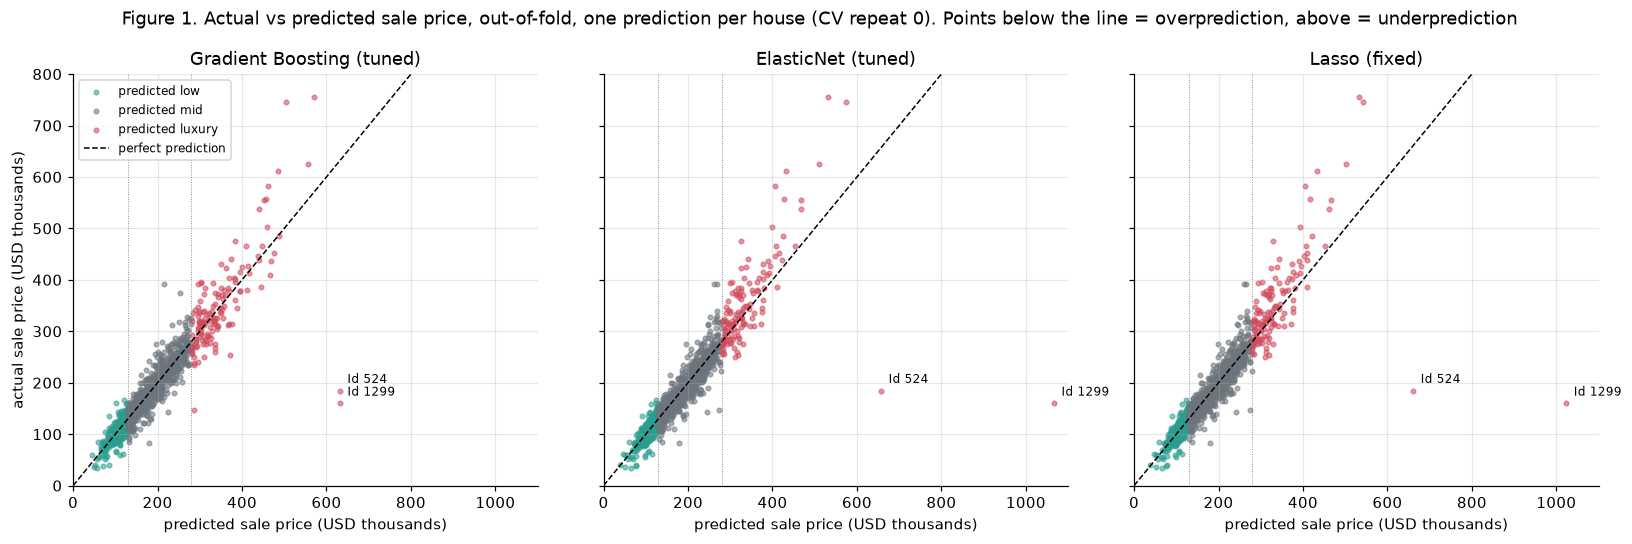

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
segcol = {'low': '#2a9d8f', 'mid': '#6c757d', 'luxury': '#d1495b'}
for ax, m in zip(axes, M):
    d = R0[R0.model == m]
    for s in E.SEGMENTS:
        g = d[d.segment_pred == s]; ax.scatter(g.pred / 1e3, g.y / 1e3, s=9, alpha=.55, color=segcol[s], label=f'predicted {s}')
    ax.plot([0, 800], [0, 800], 'k--', lw=1, label='perfect prediction')
    for e in E.SEGMENT_EDGES: ax.axvline(e / 1e3, color='grey', lw=.6, ls=':')
    for i in E.FLAGGED_IDS:
        r = d[d.Id == i].iloc[0]; ax.annotate(f'Id {i}', (r.pred / 1e3, r.y / 1e3), textcoords='offset points', xytext=(5, 5), fontsize=8)
    ax.set_title(LAB[m]); ax.set_xlabel('predicted sale price (USD thousands)'); ax.set_xlim(0, 1100); ax.set_ylim(0, 800)
axes[0].set_ylabel('actual sale price (USD thousands)'); axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle('Figure 1. Actual vs predicted sale price, out-of-fold, one prediction per house (CV repeat 0). Points below the line = overprediction, above = underprediction')
plt.tight_layout(); plt.savefig(FIG / 'final_fig1_actual_vs_predicted.png'); plt.show()

In [5]:
# Is expensive-house underprediction systematic? signed bias by band, banded on PREDICTED price (decision-time information) and on ACTUAL price (artefact)
def bias_by(d, by):
    return d.groupby(by).agg(n=('Id', 'size'), mean_resid_usd=('residual_usd', 'mean'), mean_resid_log=('residual_log', 'mean'), median_resid_log=('residual_log', 'median')).reindex(list(E.SEGMENTS))
for m in ['gbr_tuned', 'enet_tuned']:
    print(LAB[m]); display(pd.concat({'banded on PREDICTED price': bias_by(R0[R0.model == m], 'segment_pred'), 'banded on ACTUAL price (regression-to-the-mean artefact)': bias_by(R0[R0.model == m], 'segment_actual')}, axis=1).round(3))

Gradient Boosting (tuned)


banded on PREDICTED price                                                banded on ACTUAL price (regression-to-the-mean artefact)                                               
                               n mean_resid_usd mean_resid_log median_resid_log                                                        n mean_resid_usd mean_resid_log median_resid_log
low                          367       1083.752          0.000            0.016                                                      365      -5014.472         -0.047           -0.030
mid                          954       1412.219          0.002            0.006                                                      951        533.633          0.009            0.012
luxury                       139        265.535         -0.014            0.001                                                      144      21560.422          0.058            0.048

ElasticNet (tuned)


banded on PREDICTED price                                                banded on ACTUAL price (regression-to-the-mean artefact)                                               
                               n mean_resid_usd mean_resid_log median_resid_log                                                        n mean_resid_usd mean_resid_log median_resid_log
low                          387       2493.281          0.012            0.029                                                      365      -3142.897         -0.032           -0.009
mid                          942       -686.742         -0.009           -0.005                                                      951      -1808.892         -0.002            0.003
luxury                       131      11727.374          0.026            0.042                                                      144      32789.503          0.089            0.081

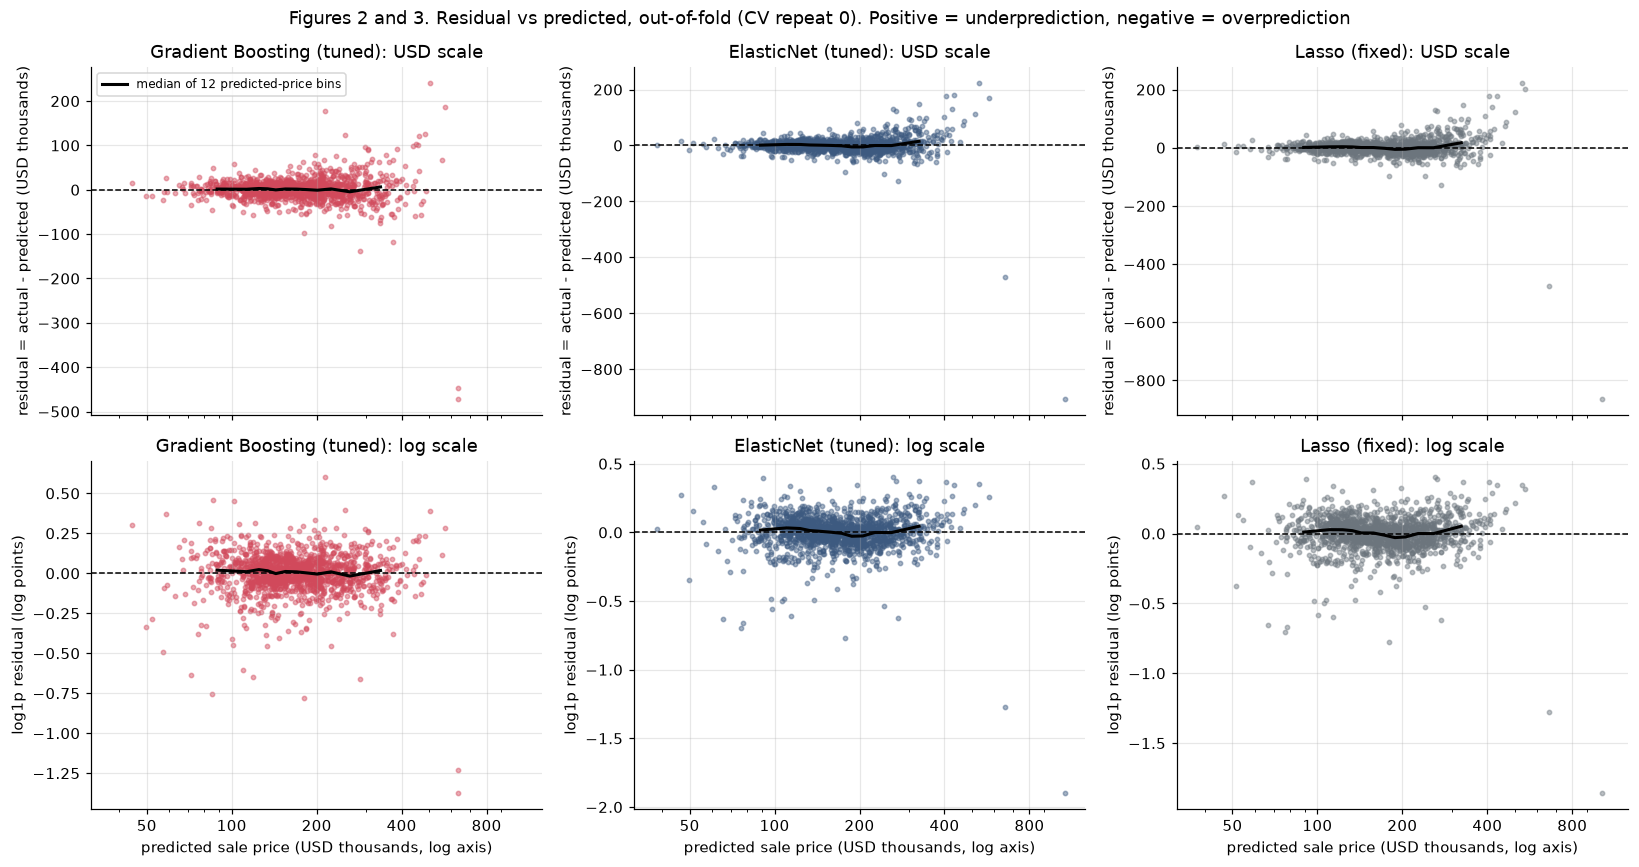

,"Spearman(|resid USD|, predicted)","Spearman(|resid log|, predicted)","Spearman(resid log, predicted)",Levene p (log resid SD equal across predicted segments),SD log resid low/mid/luxury,SD USD resid low/mid/luxury ($k)
model,,,,,,
Gradient Boosting (tuned),0.3186,-0.0161,-0.0269,0.0,0.147 / 0.104 / 0.207,14.0 / 19.8 / 75.3
ElasticNet (tuned),0.3299,0.0014,-0.0439,0.0,0.137 / 0.104 / 0.238,12.9 / 20.1 / 104.3
Lasso (fixed),0.3403,0.0112,-0.0354,0.0,0.138 / 0.104 / 0.238,12.9 / 20.0 / 102.6


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for j, m in enumerate(M):
    d = R0[R0.model == m]
    for i, (col, lab, sc) in enumerate([('residual_usd', 'residual = actual - predicted (USD thousands)', 1e3), ('residual_log', 'log1p residual (log points)', 1)]):
        ax = axes[i, j]; ax.scatter(d.pred / 1e3, d[col] / sc, s=8, alpha=.45, color=COL[m])
        q = pd.qcut(d.pred, 12, duplicates='drop'); g = d.groupby(q, observed=True)
        ax.plot(g.pred.median() / 1e3, g[col].median() / sc, 'k-', lw=2, label='median of 12 predicted-price bins')
        ax.axhline(0, color='k', lw=1, ls='--'); ax.set_xscale('log'); ax.set_xticks([50, 100, 200, 400, 800]); ax.set_xticklabels([50, 100, 200, 400, 800])
        ax.set_title(f'{LAB[m]}: ' + ('USD scale' if i == 0 else 'log scale')); ax.set_ylabel(lab);
        if i == 1: ax.set_xlabel('predicted sale price (USD thousands, log axis)')
        if i == 0 and j == 0: ax.legend(fontsize=8)
fig.suptitle('Figures 2 and 3. Residual vs predicted, out-of-fold (CV repeat 0). Positive = underprediction, negative = overprediction')
plt.tight_layout(); plt.savefig(FIG / 'final_fig2_3_residuals.png'); plt.show()
rows = []
for m in M:
    d = R0[R0.model == m]
    rows.append({'model': LAB[m], 'Spearman(|resid USD|, predicted)': stats.spearmanr(d.abs_err_usd, d.pred)[0], 'Spearman(|resid log|, predicted)': stats.spearmanr(d.residual_log.abs(), d.pred)[0],
                 'Spearman(resid log, predicted)': stats.spearmanr(d.residual_log, d.pred)[0],
                 'Levene p (log resid SD equal across predicted segments)': stats.levene(*[d[d.segment_pred == s].residual_log for s in E.SEGMENTS])[1],
                 'SD log resid low/mid/luxury': ' / '.join(f"{d[d.segment_pred == s].residual_log.std():.3f}" for s in E.SEGMENTS),
                 'SD USD resid low/mid/luxury ($k)': ' / '.join(f"{d[d.segment_pred == s].residual_usd.std() / 1e3:.1f}" for s in E.SEGMENTS)})
display(pd.DataFrame(rows).set_index('model').round(4))

,mean,median,p75,p90,p95,max,share of total |error| from worst 10% of houses,share from the 2 flagged houses
Gradient Boosting (tuned),15603.0,10061.0,18613.0,32972.0,46590.0,471499.0,0.392,0.040
ElasticNet (tuned),15943.0,9764.0,18766.0,32650.0,46468.0,906231.0,0.412,0.059
Lasso (fixed),16065.0,9786.0,18992.0,32853.0,46571.0,863323.0,0.411,0.057


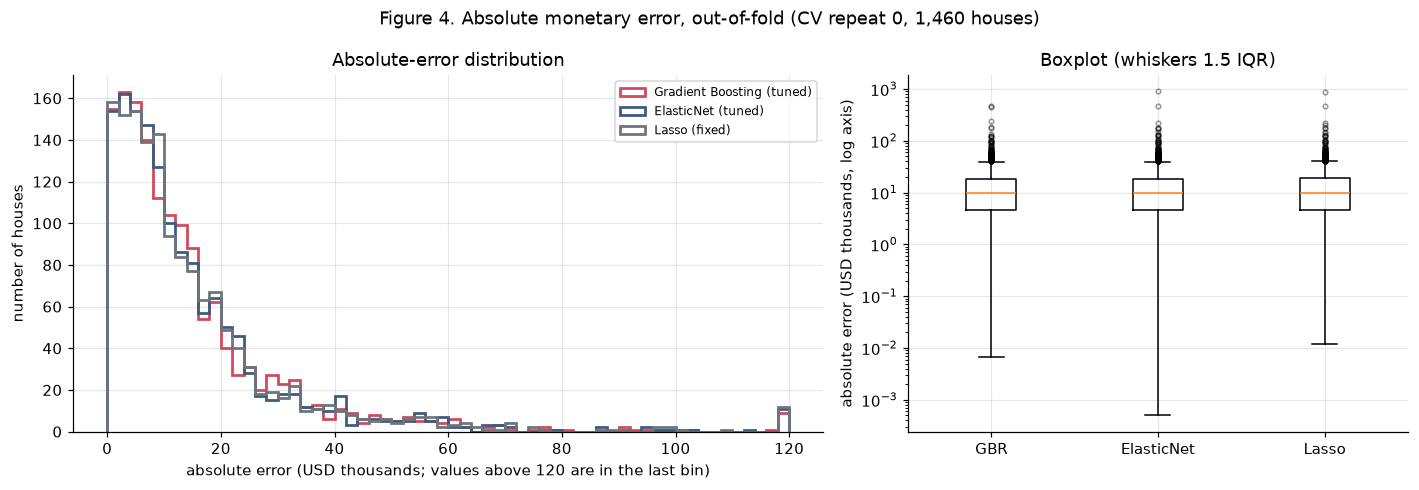

In [7]:
rows = {LAB[m]: E.error_quantiles(R0[R0.model == m].abs_err_usd) for m in M}
Q = pd.DataFrame(rows).T; Q['share of total |error| from worst 10% of houses'] = [E.concentration(R0[R0.model == m].abs_err_usd) for m in M]
Q['share from the 2 flagged houses'] = [R0[(R0.model == m) & R0.Id.isin(E.FLAGGED_IDS)].abs_err_usd.sum() / R0[R0.model == m].abs_err_usd.sum() for m in M]
display(Q.round({'mean': 0, 'median': 0, 'p75': 0, 'p90': 0, 'p95': 0, 'max': 0}).round(3))
Q.to_csv(TAB / 'final_eval_abs_error_quantiles.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.5, 1]})
bins = np.linspace(0, 120, 61)
for m in M: axes[0].hist(np.clip(R0[R0.model == m].abs_err_usd / 1e3, 0, 120), bins=bins, histtype='step', lw=1.8, color=COL[m], label=LAB[m])
axes[0].set_xlabel('absolute error (USD thousands; values above 120 are in the last bin)'); axes[0].set_ylabel('number of houses'); axes[0].set_title('Absolute-error distribution'); axes[0].legend(fontsize=8)
axes[1].boxplot([R0[R0.model == m].abs_err_usd / 1e3 for m in M], vert=True, showfliers=True, flierprops=dict(markersize=3, alpha=.4)); axes[1].set_xticks([1, 2, 3]); axes[1].set_xticklabels(['GBR', 'ElasticNet', 'Lasso'])
axes[1].set_yscale('log'); axes[1].set_ylabel('absolute error (USD thousands, log axis)'); axes[1].set_title('Boxplot (whiskers 1.5 IQR)')
fig.suptitle('Figure 4. Absolute monetary error, out-of-fold (CV repeat 0, 1,460 houses)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig4_abs_error.png'); plt.show()

,mean (MAPE),median,p90,p95,max
"APE, % (repeat 0)",,,,,
Gradient Boosting (tuned),8.90,5.91,17.84,23.83,294.69
ElasticNet (tuned),8.97,5.97,17.41,23.03,566.39
Lasso (fixed),9.01,6.09,17.32,23.13,539.58


MAPE % by segment (segments banded on tuned-GBR predicted price, so the houses are identical for all models):


segment_matched,low,mid,luxury
Gradient Boosting (tuned),10.60,7.51,14.00
ElasticNet (tuned),9.92,7.53,16.44
Lasso (fixed),9.93,7.57,16.43


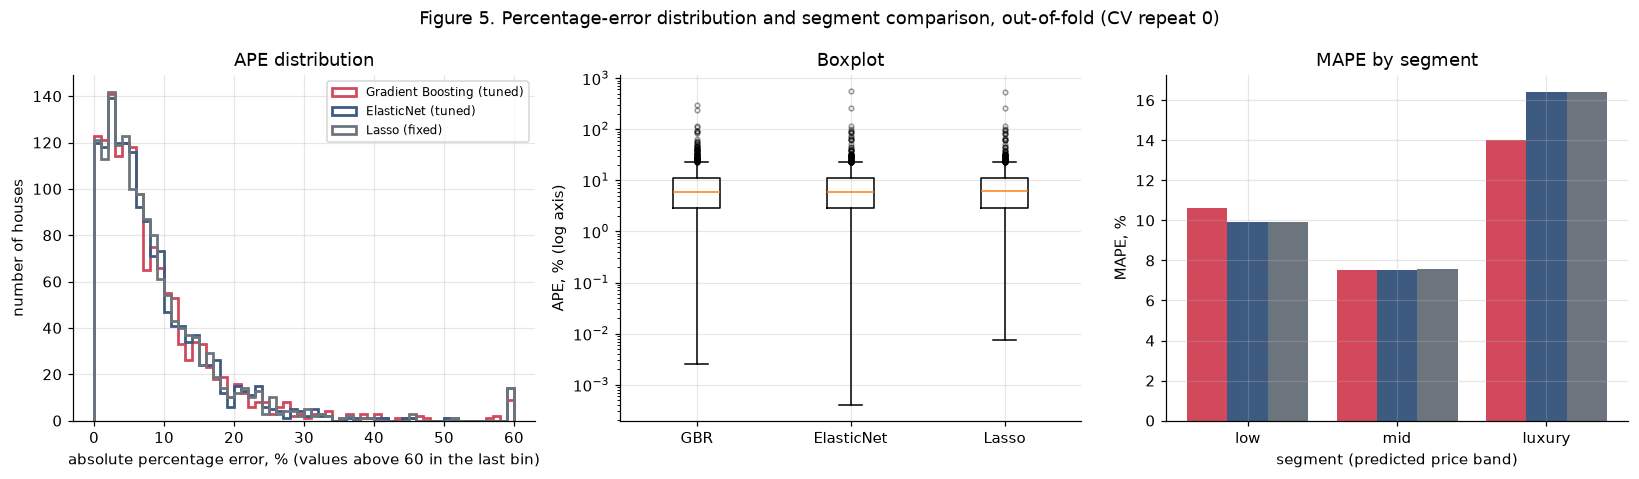

In [8]:
APE = {LAB[m]: pd.Series({'mean (MAPE)': 100 * R0[R0.model == m].ape.mean(), 'median': 100 * R0[R0.model == m].ape.median(), 'p90': 100 * np.percentile(R0[R0.model == m].ape, 90),
                          'p95': 100 * np.percentile(R0[R0.model == m].ape, 95), 'max': 100 * R0[R0.model == m].ape.max()}) for m in M}
display(pd.DataFrame(APE).T.round(2).rename_axis('APE, % (repeat 0)'))
seg_ape = R0.groupby(['model', 'segment_matched']).ape.agg(lambda a: 100 * a.mean()).unstack().reindex(columns=list(E.SEGMENTS)).loc[M]; seg_ape.index = [LAB[m] for m in seg_ape.index]
print('MAPE % by segment (segments banded on tuned-GBR predicted price, so the houses are identical for all models):'); display(seg_ape.round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for m in M: axes[0].hist(np.clip(100 * R0[R0.model == m].ape, 0, 60), bins=np.linspace(0, 60, 61), histtype='step', lw=1.8, color=COL[m], label=LAB[m])
axes[0].set_xlabel('absolute percentage error, % (values above 60 in the last bin)'); axes[0].set_ylabel('number of houses'); axes[0].set_title('APE distribution'); axes[0].legend(fontsize=8)
axes[1].boxplot([100 * R0[R0.model == m].ape for m in M], showfliers=True, flierprops=dict(markersize=3, alpha=.4)); axes[1].set_xticks([1, 2, 3]); axes[1].set_xticklabels(['GBR', 'ElasticNet', 'Lasso']); axes[1].set_yscale('log'); axes[1].set_ylabel('APE, % (log axis)'); axes[1].set_title('Boxplot')
w = .27
for k, m in enumerate(M): axes[2].bar(np.arange(3) + (k - 1) * w, [100 * R0[(R0.model == m) & (R0.segment_matched == s)].ape.mean() for s in E.SEGMENTS], w, color=COL[m], label=LAB[m])
axes[2].set_xticks(range(3)); axes[2].set_xticklabels(['low', 'mid', 'luxury']); axes[2].set_ylabel('MAPE, %'); axes[2].set_xlabel('segment (predicted price band)'); axes[2].set_title('MAPE by segment')
fig.suptitle('Figure 5. Percentage-error distribution and segment comparison, out-of-fold (CV repeat 0)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig5_ape.png'); plt.show()

In [9]:
def seg_all(oof, by='segment_matched'):
    out = {m: E.segment_table(oof, m, by) for m in M}
    return pd.concat(out, names=['model']).rename(index=LAB, level=0)
ST = seg_all(OOF)
display(ST[['n', 'rmse_log', 'mae', 'median_ae', 'rmse_usd', 'mape', 'bias_usd', 'bias_log']].round({'n': 0, 'rmse_log': 3, 'mae': 0, 'median_ae': 0, 'rmse_usd': 0, 'mape': 2, 'bias_usd': 0, 'bias_log': 3}))
ST.round(4).to_csv(TAB / 'final_eval_segments_matched.csv')
rows = []
for m in M:
    for stat in ['mae', 'bias_usd']:
        c = E.bootstrap_segment_ci(OOF.assign(segment_pred=OOF.segment_matched), m, stat=stat)
        for s, r in c.iterrows(): rows.append(dict(model=LAB[m], segment=s, stat=stat, n_houses=int(r.n_houses), lo=r.ci_lo, hi=r.ci_hi))
BC = pd.DataFrame(rows).pivot_table(index=['segment', 'stat'], columns='model', values=['lo', 'hi'])
print('95% bootstrap intervals over houses (USD):'); display(BC.round(0).reindex(list(E.SEGMENTS), level=0))
print('Same table with each model banded on its OWN predicted price (not matched; the project rule, shown for reference):')
display(seg_all(OOF, 'segment_pred')[['n', 'rmse_log', 'mae', 'rmse_usd', 'mape', 'bias_usd']].round({'n': 0, 'rmse_log': 3, 'mae': 0, 'rmse_usd': 0, 'mape': 2, 'bias_usd': 0}))

n  rmse_log      mae  median_ae  rmse_usd   mape  bias_usd  bias_log
model                     segment_matched                                                                          
Gradient Boosting (tuned) low              371.0     0.150  10280.0     7530.0   14076.0  10.63     972.0    -0.001
                          mid              947.0     0.103  13563.0     9471.0   19847.0   7.38    1289.0     0.002
                          luxury           142.0     0.189  42402.0    27374.0   69202.0  13.06    5045.0    -0.003
ElasticNet (tuned)        low              371.0     0.145   9914.0     7357.0   13456.0  10.29    1043.0    -0.000
                          mid              947.0     0.102  13616.0    10029.0   19046.0   7.55    -550.0    -0.007
                          luxury           142.0     0.237  49077.0    27830.0   98227.0  15.90   16542.0     0.038
Lasso (fixed)             low              371.0     0.142   9803.0     7183.0   13278.0  10.11    1189.0     0.002
                          mid              947.0     0.101  13504.0     9921.0   18906.0   7.49    -540.0    -0.007
                          luxury           142.0     0.236  48944.0    28502.0   97402.0  15.79   16783.0     0.038

95% bootstrap intervals over houses (USD):


hi                                                         lo                                        
model            ElasticNet (tuned) Gradient Boosting (tuned) Lasso (fixed) ElasticNet (tuned) Gradient Boosting (tuned) Lasso (fixed)
segment stat                                                                                                                          
low     bias_usd             2804.0                    2526.0        2765.0               92.0                    -393.0          47.0
        mae                 10541.0                   11306.0       10518.0             8764.0                    9422.0        8746.0
mid     bias_usd              677.0                    2683.0         665.0            -1666.0                     223.0       -1683.0
        mae                 14381.0                   14636.0       14474.0            12701.0                   12817.0       12810.0
luxury  bias_usd            27252.0                   11740.0       29024.0            -4594.0                  -12255.0       -2359.0
        mae                 65976.0                   53212.0       66097.0            36252.0                   33176.0       37041.0

Same table with each model banded on its OWN predicted price (not matched; the project rule, shown for reference):


n  rmse_log      mae  rmse_usd   mape  bias_usd
model                     segment_pred                                                     
Gradient Boosting (tuned) low           371.0     0.150  10280.0   14076.0  10.63     972.0
                          mid           947.0     0.103  13563.0   19847.0   7.38    1289.0
                          luxury        142.0     0.189  42402.0   69202.0  13.06    5045.0
ElasticNet (tuned)        low           389.0     0.143  10105.0   13520.0  10.22    2383.0
                          mid           942.0     0.104  13927.0   19987.0   7.62    -727.0
                          luxury        129.0     0.239  50235.0  101492.0  16.07   15309.0
Lasso (fixed)             low           389.0     0.140   9974.0   13352.0  10.04    2458.0
                          mid           941.0     0.103  13836.0   19876.0   7.57    -692.0
                          luxury        130.0     0.237  49710.0  100231.0  15.84   15424.0

In [10]:
STx = seg_all(OOF[~OOF.Id.isin(E.FLAGGED_IDS)])
print('Same matched segments WITHOUT the two flagged houses in the scored rows (evaluation-only exclusion; predictions unchanged):')
display(STx[['n', 'rmse_log', 'mae', 'rmse_usd', 'mape', 'bias_usd', 'bias_log']].round({'n': 0, 'rmse_log': 3, 'mae': 0, 'rmse_usd': 0, 'mape': 2, 'bias_usd': 0, 'bias_log': 3}))
STx.round(4).to_csv(TAB / 'final_eval_segments_matched_without_flagged.csv')

Same matched segments WITHOUT the two flagged houses in the scored rows (evaluation-only exclusion; predictions unchanged):


n  rmse_log      mae  rmse_usd   mape  bias_usd  bias_log
model                     segment_matched                                                               
Gradient Boosting (tuned) low              371.0     0.150  10280.0   14076.0  10.63     972.0    -0.001
                          mid              947.0     0.103  13563.0   19847.0   7.38    1289.0     0.002
                          luxury           140.0     0.149  38833.0   58415.0  10.82    9292.0     0.011
ElasticNet (tuned)        low              371.0     0.145   9914.0   13456.0  10.29    1043.0    -0.000
                          mid              947.0     0.102  13616.0   19046.0   7.55    -550.0    -0.007
                          luxury           140.0     0.153  40932.0   60214.0  10.85   25624.0     0.060
Lasso (fixed)             low              371.0     0.142   9803.0   13278.0  10.11    1189.0     0.002
                          mid              947.0     0.101  13504.0   18906.0   7.49    -540.0    -0.007
                          luxury           140.0     0.154  40965.0   60870.0  10.83   25702.0     0.060

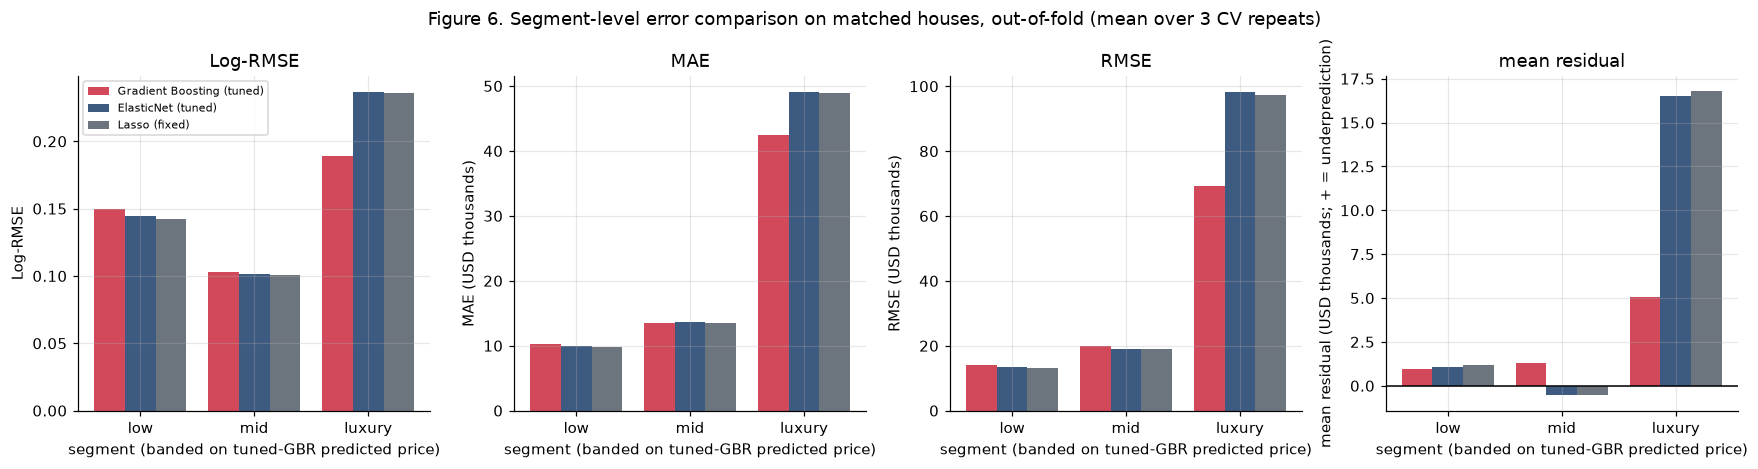

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
w = .27
for ax, (key, lab, sc) in zip(axes, [('rmse_log', 'Log-RMSE', 1), ('mae', 'MAE (USD thousands)', 1e3), ('rmse_usd', 'RMSE (USD thousands)', 1e3), ('bias_usd', 'mean residual (USD thousands; + = underprediction)', 1e3)]):
    for k, m in enumerate(M):
        ax.bar(np.arange(3) + (k - 1) * w, [ST.loc[(LAB[m], s), key] / sc for s in E.SEGMENTS], w, color=COL[m], label=LAB[m])
    ax.set_xticks(range(3)); ax.set_xticklabels(['low', 'mid', 'luxury']); ax.set_xlabel('segment (banded on tuned-GBR predicted price)'); ax.set_ylabel(lab); ax.set_title(lab.split(' (')[0])
    if key == 'bias_usd': ax.axhline(0, color='k', lw=1)
axes[0].legend(fontsize=7)
fig.suptitle('Figure 6. Segment-level error comparison on matched houses, out-of-fold (mean over 3 CV repeats)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig6_segments.png'); plt.show()

In [12]:
g = R0[R0.model == 'gbr_tuned'].merge(df[['Id', 'OverallQual', 'GrLivArea', 'Neighborhood', 'YearBuilt', 'TotalBsmtSF', 'GarageCars', 'LotArea', 'SaleCondition']], on='Id')
g['GrLivArea pctile'] = g.GrLivArea.rank(pct=True) * 100
g['flagged (D2)'] = g.Id.isin(E.FLAGGED_IDS)
show = ['Id', 'y', 'pred', 'residual_usd', 'abs_err_usd', 'ape', 'segment_pred', 'OverallQual', 'GrLivArea', 'GrLivArea pctile', 'Neighborhood', 'YearBuilt', 'TotalBsmtSF', 'GarageCars', 'LotArea', 'SaleCondition', 'flagged (D2)']
A = g.nlargest(15, 'abs_err_usd')[show].round({'y': 0, 'pred': 0, 'residual_usd': 0, 'abs_err_usd': 0, 'ape': 2, 'GrLivArea pctile': 0})
Bp = g.nlargest(15, 'ape')[show].round({'y': 0, 'pred': 0, 'residual_usd': 0, 'abs_err_usd': 0, 'ape': 2, 'GrLivArea pctile': 0})
print('A. Largest absolute USD errors (SaleCondition shown for diagnosis only; it is not a model input)'); display(A.set_index('Id'))
print('B. Largest absolute percentage errors'); display(Bp.set_index('Id'))
A.to_csv(TAB / 'final_eval_largest_abs_errors.csv'); Bp.to_csv(TAB / 'final_eval_largest_ape_errors.csv')
print('Overlap between the two top-15 lists (Ids):', sorted(set(A.Id) & set(Bp.Id)))
for lab, d in [('top-15 |USD| errors', A), ('top-15 APE', Bp)]:
    print(f'{lab}: share overpredicted = {(d.residual_usd < 0).mean():.2f}; share with SaleCondition Partial/Abnorml = {d.SaleCondition.isin(["Partial", "Abnorml"]).mean():.2f}; median OverallQual = {d.OverallQual.median()}')
print('For reference, whole sample: share SaleCondition Partial/Abnormal =', round(df.SaleCondition.isin(['Partial', 'Abnorml']).mean(), 3))
print(f'Sparsity of very large houses: {int((df.GrLivArea > 4000).sum())} of 1,460 houses have GrLivArea > 4,000 sq ft; median GrLivArea percentile of the 15 largest USD errors = {A["GrLivArea pctile"].median():.0f}')

A. Largest absolute USD errors (SaleCondition shown for diagnosis only; it is not a model input)


,y,pred,residual_usd,abs_err_usd,ape,segment_pred,OverallQual,GrLivArea,GrLivArea pctile,Neighborhood,YearBuilt,TotalBsmtSF,GarageCars,LotArea,SaleCondition,flagged (D2)
Id,,,,,,,,,,,,,,,,
1299,160000.0,631499.0,-471499.0,471499.0,2.95,luxury,10,5642,100.0,Edwards,2008,6110,2,63887,Partial,True
524,184750.0,631541.0,-446791.0,446791.0,2.42,luxury,10,4676,100.0,Edwards,2007,3138,3,40094,Partial,True
1183,745000.0,503948.0,241052.0,241052.0,0.32,luxury,10,4476,100.0,NoRidge,1996,2396,3,15623,Abnorml,False
692,755000.0,569448.0,185552.0,185552.0,0.25,luxury,10,4316,100.0,NoRidge,1994,2444,3,21535,Normal,False
689,392000.0,214413.0,177587.0,177587.0,0.45,mid,8,1419,47.0,StoneBr,2007,1419,2,8089,Partial,False
1325,147000.0,285165.0,-138165.0,138165.0,0.94,luxury,8,1795,76.0,Somerst,2006,1795,3,9986,Partial,False
899,611657.0,485119.0,126538.0,126538.0,0.21,luxury,9,2364,94.0,NridgHt,2009,2330,3,12919,Partial,False
314,375000.0,252595.0,122405.0,122405.0,0.33,mid,7,2036,87.0,Timber,1965,2136,2,215245,Normal,False
804,582933.0,462362.0,120571.0,120571.0,0.21,luxury,9,2822,98.0,NridgHt,2008,1734,3,13891,Partial,False


B. Largest absolute percentage errors


,y,pred,residual_usd,abs_err_usd,ape,segment_pred,OverallQual,GrLivArea,GrLivArea pctile,Neighborhood,YearBuilt,TotalBsmtSF,GarageCars,LotArea,SaleCondition,flagged (D2)
Id,,,,,,,,,,,,,,,,
1299,160000.0,631499.0,-471499.0,471499.0,2.95,luxury,10,5642,100.0,Edwards,2008,6110,2,63887,Partial,True
524,184750.0,631541.0,-446791.0,446791.0,2.42,luxury,10,4676,100.0,Edwards,2007,3138,3,40094,Partial,True
633,82500.0,179775.0,-97275.0,97275.0,1.18,mid,7,1411,46.0,NWAmes,1977,1386,2,11900,Family,False
31,40000.0,84831.0,-44831.0,44831.0,1.12,low,4,1317,39.0,IDOTRR,1920,649,1,8500,Normal,False
1325,147000.0,285165.0,-138165.0,138165.0,0.94,luxury,8,1795,76.0,Somerst,2006,1795,3,9986,Partial,False
463,62383.0,119204.0,-56821.0,56821.0,0.91,low,5,864,7.0,Sawyer,1965,864,1,8281,Normal,False
969,37900.0,71559.0,-33659.0,33659.0,0.89,low,3,968,13.0,OldTown,1910,600,0,5925,Abnorml,False
411,60000.0,110052.0,-50052.0,50052.0,0.83,low,5,1276,36.0,Edwards,1958,1276,1,9571,Abnorml,False
496,34900.0,56953.0,-22053.0,22053.0,0.63,low,4,720,1.0,IDOTRR,1920,720,0,7879,Abnorml,False


Overlap between the two top-15 lists (Ids): [524, 633, 1299, 1325]
top-15 |USD| errors: share overpredicted = 0.33; share with SaleCondition Partial/Abnorml = 0.67; median OverallQual = 9.0
top-15 APE: share overpredicted = 1.00; share with SaleCondition Partial/Abnorml = 0.67; median OverallQual = 5.0
For reference, whole sample: share SaleCondition Partial/Abnormal = 0.155
Sparsity of very large houses: 4 of 1,460 houses have GrLivArea > 4,000 sq ft; median GrLivArea percentile of the 15 largest USD errors = 94


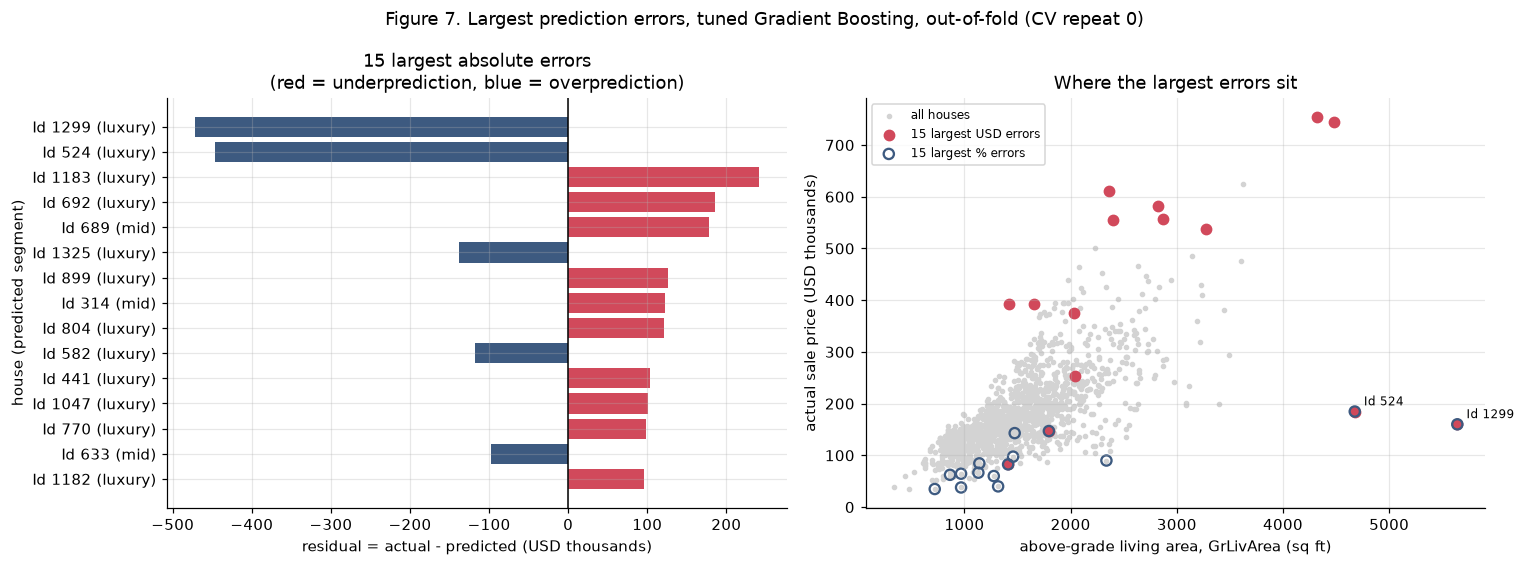

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
top = g.nlargest(15, 'abs_err_usd').iloc[::-1]
axes[0].barh([f"Id {i} ({q})" for i, q in zip(top.Id, top.segment_pred)], top.residual_usd / 1e3, color=['#d1495b' if r > 0 else '#3d5a80' for r in top.residual_usd])
axes[0].axvline(0, color='k', lw=1); axes[0].set_xlabel('residual = actual - predicted (USD thousands)'); axes[0].set_ylabel('house (predicted segment)')
axes[0].set_title('15 largest absolute errors\n(red = underprediction, blue = overprediction)')
axes[1].scatter(g.GrLivArea, g.y / 1e3, s=7, color='lightgrey', label='all houses')
t2 = g.nlargest(15, 'abs_err_usd'); axes[1].scatter(t2.GrLivArea, t2.y / 1e3, s=45, color='#d1495b', label='15 largest USD errors')
t3 = g.nlargest(15, 'ape'); axes[1].scatter(t3.GrLivArea, t3.y / 1e3, s=45, facecolors='none', edgecolors='#3d5a80', linewidth=1.5, label='15 largest % errors')
for i in E.FLAGGED_IDS:
    r = g[g.Id == i].iloc[0]; axes[1].annotate(f'Id {i}', (r.GrLivArea, r.y / 1e3), textcoords='offset points', xytext=(6, 4), fontsize=8)
axes[1].set_xlabel('above-grade living area, GrLivArea (sq ft)'); axes[1].set_ylabel('actual sale price (USD thousands)'); axes[1].set_title('Where the largest errors sit'); axes[1].legend(fontsize=8)
fig.suptitle('Figure 7. Largest prediction errors, tuned Gradient Boosting, out-of-fold (CV repeat 0)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig7_largest_errors.png'); plt.show()

In [14]:
def metr(fm): return fm.groupby('model')[['rmse_log', 'mae', 'rmse_usd', 'mape', 'r2_usd']].mean()
P_ = metr(E.fold_metrics(OOF)); E_ = metr(E.fold_metrics(OOF, E.FLAGGED_IDS))
# (T): swap in the training-exclusion predictions for the two tuned models
T_all, T_ex = {}, {}
for fam, mod in [('gbr', 'gbr_tuned'), ('elasticnet', 'enet_tuned')]:
    d = OOF[OOF.model == mod][['model', 'fold', 'repeat', 'row', 'Id', 'y']].merge(RF[RF.family == fam][['fold', 'row', 'pred_log_trainexcl']], on=['fold', 'row']).rename(columns={'pred_log_trainexcl': 'pred_log'})
    d = E.add_errors(d)
    T_all[mod] = metr(E.fold_metrics(d)).loc[mod]; T_ex[mod] = metr(E.fold_metrics(d, E.FLAGGED_IDS)).loc[mod]
rows = []
for m in M:
    rows.append({'model': LAB[m], 'condition': 'P  primary: all houses', **P_.loc[m].to_dict()})
    rows.append({'model': LAB[m], 'condition': 'E  evaluation-only exclusion of 524, 1299', **E_.loc[m].to_dict()})
    if m in T_all:
        rows.append({'model': LAB[m], 'condition': 'T  training exclusion; scored on all houses', **T_all[m].to_dict()})
        rows.append({'model': LAB[m], 'condition': 'T  training exclusion; scored without 524, 1299', **T_ex[m].to_dict()})
SENS = pd.DataFrame(rows).set_index(['model', 'condition']); display(SENS.round({'rmse_log': 4, 'mae': 0, 'rmse_usd': 0, 'mape': 2, 'r2_usd': 3}))
SENS.round(4).to_csv(TAB / 'final_eval_outlier_sensitivity.csv')
fmE = E.fold_metrics(OOF, E.FLAGGED_IDS); mE = {m: fmE[fmE.model == m].sort_values('fold').reset_index(drop=True) for m in M}
pE = F.paired_vs_reference(mE, 'gbr_tuned')
print('Paired differences vs tuned Gradient Boosting WITHOUT the two houses in the validation rows (diff > 0: worse than GBR):')
display(pE.loc[['enet_tuned', 'lasso_fixed'], ['rmse_log', 'diff', 'ci_lo', 'ci_hi', 'folds_better', 'verdict']].rename(index=LAB).round(4))
fl = OOF[OOF.Id.isin(E.FLAGGED_IDS) & (OOF.repeat == 0)].pivot(index='Id', columns='model', values='pred').loc[:, M].rename(columns=LAB)
fl.insert(0, 'actual', df.set_index('Id').loc[fl.index, 'SalePrice']); print('Predictions for the two houses (USD, out-of-fold):'); display(fl.round(0))

rmse_log      mae  rmse_usd  mape  r2_usd
model                     condition                                                                                 
Gradient Boosting (tuned) P  primary: all houses                             0.1260  15535.0   26774.0  8.76   0.884
                          E  evaluation-only exclusion of 524, 1299          0.1210  15158.0   24708.0  8.54   0.902
                          T  training exclusion; scored on all houses        0.1267  15163.0   28109.0  8.69   0.868
                          T  training exclusion; scored without 524, 1299    0.1170  14500.0   22766.0  8.30   0.917
ElasticNet (tuned)        P  primary: all houses                             0.1307  16125.0   32014.0  9.06   0.822
                          E  evaluation-only exclusion of 524, 1299          0.1190  15299.0   24704.0  8.57   0.902
                          T  training exclusion; scored on all houses        0.1305  15896.0   33024.0  9.07   0.795
                          T  training exclusion; scored without 524, 1299    0.1167  14896.0   23057.0  8.47   0.915
Lasso (fixed)             P  primary: all houses                             0.1295  16011.0   31768.0  8.96   0.825
                          E  evaluation-only exclusion of 524, 1299          0.1180  15201.0   24729.0  8.48   0.902

Paired differences vs tuned Gradient Boosting WITHOUT the two houses in the validation rows (diff > 0: worse than GBR):


,rmse_log,diff,ci_lo,ci_hi,folds_better,verdict
variant,,,,,,
ElasticNet (tuned),0.119,-0.002,-0.0087,0.0048,9,tie
Lasso (fixed),0.118,-0.003,-0.0087,0.0027,10,tie


Predictions for the two houses (USD, out-of-fold):


model,actual,Gradient Boosting (tuned),ElasticNet (tuned),Lasso (fixed)
Id,,,,
524,184750,631541.0,656874.0,660801.0
1299,160000,631499.0,1066231.0,1023323.0


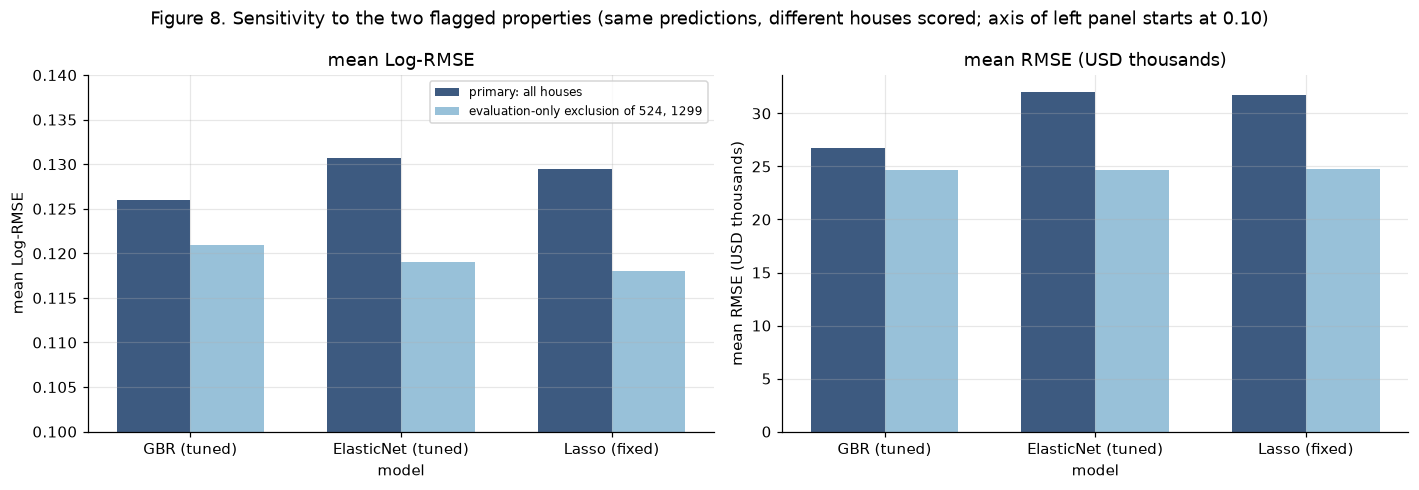

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
conds = ['P  primary: all houses', 'E  evaluation-only exclusion of 524, 1299']
w = .35
for ax, key, lab, sc in zip(axes, ['rmse_log', 'rmse_usd'], ['mean Log-RMSE', 'mean RMSE (USD thousands)'], [1, 1e3]):
    for k, c in enumerate(conds):
        ax.bar(np.arange(3) + (k - .5) * w, [SENS.loc[(LAB[m], c), key] / sc for m in M], w, label=c.split('  ')[1], color=['#3d5a80', '#98c1d9'][k])
    ax.set_xticks(range(3)); ax.set_xticklabels(['GBR (tuned)', 'ElasticNet (tuned)', 'Lasso (fixed)']); ax.set_ylabel(lab); ax.set_xlabel('model'); ax.set_title(lab)
axes[0].legend(fontsize=8); axes[0].set_ylim(.10, .14)
fig.suptitle('Figure 8. Sensitivity to the two flagged properties (same predictions, different houses scored; axis of left panel starts at 0.10)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig8_outlier_sensitivity.png'); plt.show()

Final ElasticNet (alpha 9.43e-04, l1_ratio 0.90) fitted on all 1,460 rows: 63 of 172 coefficients non-zero
Verification: max |z - (g(x) - centre)/scale| over numeric columns = 0.0e+00; max |predict - (intercept + Z.coef)| = 0.0e+00


,kind,coef_per_sd,coef_model_units,coef_original_units,approx_pct_effect,log1p_input,unit_note
feature,,,,,,,
GrLivArea,numeric,0.1407,0.1911,0.4222,NaN,True,per unit of log1p(x): ~ elasticity
OverallQual,numeric,0.0748,0.1082,0.0541,5.5600,False,per original unit
OverallCond,numeric,0.0449,0.0404,0.0404,4.1184,False,per original unit
HouseAge,numeric,-0.0426,-0.0648,-0.0014,-0.1409,False,per original unit
LotArea,numeric,0.0404,0.0335,0.0780,NaN,True,per unit of log1p(x): ~ elasticity
GarageCars,numeric,0.0383,0.0512,0.0512,5.2579,False,per original unit
TotalBathrooms,numeric,0.0312,0.0198,0.0397,4.0474,False,per original unit
Neighborhood_NridgHt,one-hot indicator,0.0215,0.0961,0.0961,10.0828,False,"approx. multiplicative association: exp(coef)-1, no single referen..."
MSZoning_C (all),one-hot indicator,-0.0214,-0.2591,-0.2591,-22.8284,False,"approx. multiplicative association: exp(coef)-1, no single referen..."


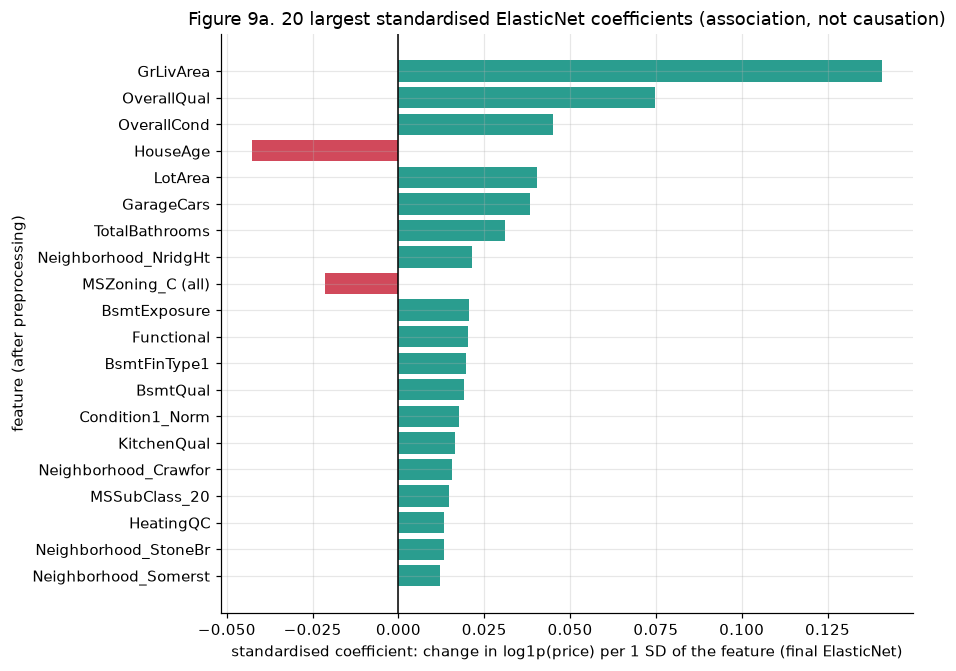

In [16]:
EN = joblib.load(NT.OUT / 'final_model_elasticnet_tuning_v1.joblib'); GB = joblib.load(NT.OUT / 'final_model_gbr_tuning_v1.joblib')
CT, info, Z = E.coefficient_table(EN, X)
worst = E.verify_numeric_conversion(EN, X, info, Z)
ident = np.abs(EN['model'].predict(Z.values) - (EN['model'].intercept_ + Z.values @ EN['model'].coef_)).max()
print(f"Final ElasticNet (alpha {EN['model'].alpha:.2e}, l1_ratio {EN['model'].l1_ratio:.2f}) fitted on all 1,460 rows: {int((EN['model'].coef_ != 0).sum())} of {len(EN['model'].coef_)} coefficients non-zero")
print(f'Verification: max |z - (g(x) - centre)/scale| over numeric columns = {worst:.1e}; max |predict - (intercept + Z.coef)| = {ident:.1e}')
view = CT[CT.coef_model_units != 0].head(20)[['feature', 'kind', 'coef_per_sd', 'coef_model_units', 'coef_original_units', 'approx_pct_effect', 'log1p_input', 'unit_note']]
display(view.round(4).set_index('feature'))
CT.round(5).to_csv(TAB / 'final_eval_elasticnet_coefficients.csv', index=False)
fig, ax = plt.subplots(figsize=(8.5, 6.2))
v = CT[CT.coef_model_units != 0].head(20).iloc[::-1]
ax.barh(v.feature, v.coef_per_sd, color=['#2a9d8f' if c > 0 else '#d1495b' for c in v.coef_per_sd])
ax.axvline(0, color='k', lw=1); ax.set_xlabel('standardised coefficient: change in log1p(price) per 1 SD of the feature (final ElasticNet)'); ax.set_ylabel('feature (after preprocessing)')
ax.set_title('Figure 9a. 20 largest standardised ElasticNet coefficients (association, not causation)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig9a_coefficients.png'); plt.show()

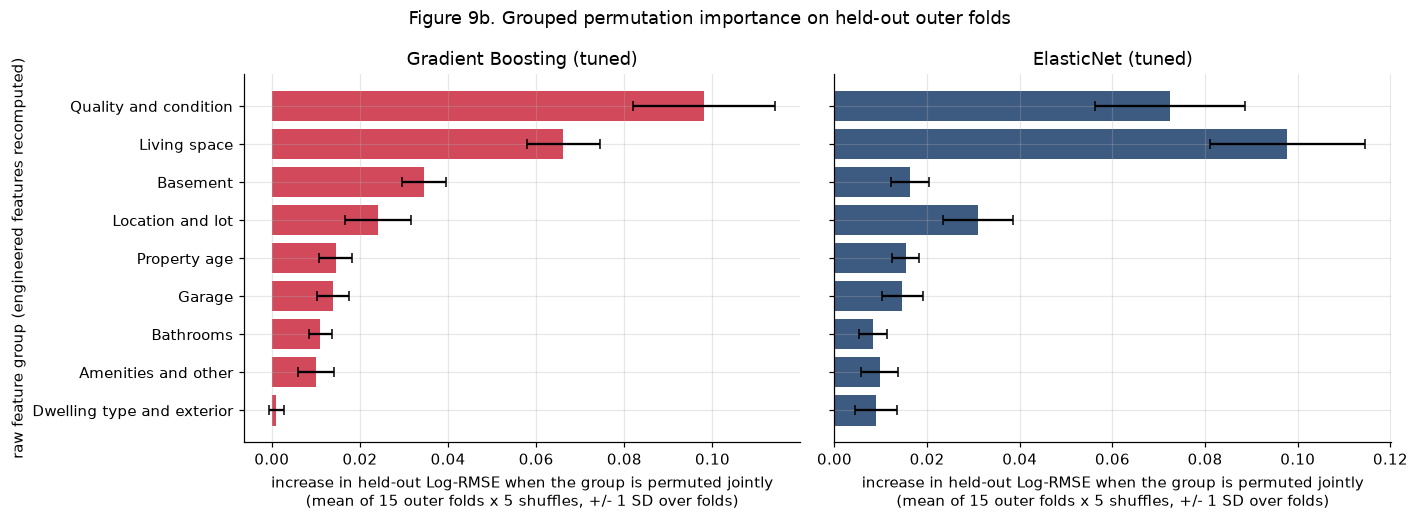

family,ElasticNet delta Log-RMSE,GBR delta Log-RMSE,rank GBR,rank ElasticNet
group,,,,
Quality and condition,0.0723,0.0981,1,2
Living space,0.0977,0.0661,2,1
Basement,0.0163,0.0346,3,4
Location and lot,0.0309,0.0240,4,3
Property age,0.0154,0.0145,5,5
Garage,0.0146,0.0138,6,6
Bathrooms,0.0083,0.0110,7,9
Amenities and other,0.0098,0.0100,8,7
Dwelling type and exterior,0.0090,0.0010,9,8


Groups used: {'Garage': 7, 'Living space': 7, 'Basement': 9, 'Bathrooms': 4, 'Property age': 2, 'Quality and condition': 6, 'Location and lot': 9, 'Dwelling type and exterior': 9, 'Amenities and other': 13}


In [17]:
pi = PERM.groupby(['family', 'group']).delta_logrmse.agg(['mean', 'std']).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
order = pi[pi.family == 'gbr'].sort_values('mean').group.tolist()
for ax, fam, m in zip(axes, ['gbr', 'elasticnet'], ['gbr_tuned', 'enet_tuned']):
    d = pi[pi.family == fam].set_index('group').loc[order]
    ax.barh(order, d['mean'], xerr=d['std'], color=COL[m], capsize=3)
    ax.set_title(LAB[m]); ax.set_xlabel('increase in held-out Log-RMSE when the group is permuted jointly\n(mean of 15 outer folds x 5 shuffles, +/- 1 SD over folds)')
axes[0].set_ylabel('raw feature group (engineered features recomputed)')
fig.suptitle('Figure 9b. Grouped permutation importance on held-out outer folds'); plt.tight_layout(); plt.savefig(FIG / 'final_fig9b_permutation.png'); plt.show()
w = pi.pivot(index='group', columns='family', values='mean').loc[order[::-1]]; w['rank GBR'] = w.gbr.rank(ascending=False).astype(int); w['rank ElasticNet'] = w.elasticnet.rank(ascending=False).astype(int)
display(w.rename(columns={'gbr': 'GBR delta Log-RMSE', 'elasticnet': 'ElasticNet delta Log-RMSE'}).round(4))
print('Groups used:', {g: len(c) for g, c in E.PERM_GROUPS.items()})

In [18]:
AB = pd.read_csv(ROOT / 'artifacts' / 'feature_selection' / 'ablation_folds.csv')
rows = []
for g, v in [('A_garage', 'neither'), ('B_living', 'neither'), ('B_living', 'TotRmsAbvGrd only'), ('F_bathrooms', 'none')]:
    for m in ['ridge', 'gbr']:
        ref = AB[(AB.model == m) & (AB.group == g) & AB.variant.str.contains('reference')].sort_values('fold').rmse_log.values
        c = AB[(AB.model == m) & (AB.group == g) & (AB.variant == v)].sort_values('fold').rmse_log.values
        rows.append(dict(group_removed=g, variant=v, model={'ridge': 'Ridge (alpha 10)', 'gbr': 'GBR (nb03 config)'}[m], delta_logrmse_vs_reference=(c - ref).mean(), folds_worse=int(((c - ref) > 0).sum())))
display(pd.DataFrame(rows).round(4).set_index(['group_removed', 'variant', 'model']))

delta_logrmse_vs_reference  folds_worse
group_removed variant           model                                                     
A_garage      neither           Ridge (alpha 10)                       0.0020           13
                                GBR (nb03 config)                      0.0022           15
B_living      neither           Ridge (alpha 10)                       0.0159           15
                                GBR (nb03 config)                      0.0086           15
              TotRmsAbvGrd only Ridge (alpha 10)                       0.0119           15
                                GBR (nb03 config)                      0.0067           15
F_bathrooms   none              Ridge (alpha 10)                       0.0013           13
                                GBR (nb03 config)                      0.0010           10

In [19]:
CX = E.complexity(EN, GB, X)
outer = pd.read_csv(NT.OUT / 'nested_outer_folds.csv')
cost = pd.DataFrame({
    'tuning cost per outer fold (s)': {LAB['gbr_tuned']: outer[outer.family == 'gbr'].tune_time.mean(), LAB['enet_tuned']: outer[outer.family == 'elasticnet'].tune_time.mean(), LAB['lasso_fixed']: 0.0},
    'one refit (s)': {LAB['gbr_tuned']: outer[outer.family == 'gbr'].refit_time.mean(), LAB['enet_tuned']: outer[outer.family == 'elasticnet'].refit_time.mean(), LAB['lasso_fixed']: pd.read_csv(B.OUT / 'expA_folds.csv').query('model == "lasso"').fit_time.mean()},
    'predict 292 houses incl. preprocessing (s)': {LAB['gbr_tuned']: CX['gbr_tuned']['predict_292_rows_s'], LAB['enet_tuned']: CX['enet_tuned']['predict_292_rows_s'], LAB['lasso_fixed']: np.nan},
    'complexity indicator': {LAB['gbr_tuned']: f"{CX['gbr_tuned']['n_trees']} trees, {CX['gbr_tuned']['n_parameters_total']:,} tree nodes (depth {GB['params']['max_depth']})", LAB['enet_tuned']: f"{CX['enet_tuned']['n_nonzero']} non-zero of {CX['enet_tuned']['n_parameters_total'] - 1} coefficients", LAB['lasso_fixed']: 'sparse linear (fixed alpha 1e-3)'},
    'reproducibility': {LAB['gbr_tuned']: 'seeded; deterministic, but ULP-sensitive (see section 14 note)', LAB['enet_tuned']: 'deterministic convex fit', LAB['lasso_fixed']: 'deterministic convex fit'}})
display(cost.round(3))
print('Prediction time is dominated by the shared preprocessing pipeline, not the model. Seeds: folds 42, models 42, TPE 42 + fold; all recorded in the run metadata.')

,tuning cost per outer fold (s),one refit (s),predict 292 houses incl. preprocessing (s),complexity indicator,reproducibility
Gradient Boosting (tuned),294.762,2.985,0.052,"500 trees, 11,842 tree nodes (depth 4)","seeded; deterministic, but ULP-sensitive (see section 14 note)"
ElasticNet (tuned),34.315,1.451,0.051,63 non-zero of 172 coefficients,deterministic convex fit
Lasso (fixed),0.000,0.511,NaN,sparse linear (fixed alpha 1e-3),deterministic convex fit


Prediction time is dominated by the shared preprocessing pipeline, not the model. Seeds: folds 42, models 42, TPE 42 + fold; all recorded in the run metadata.


In [20]:
FMm = E.fold_metrics(OOF); FMe = E.fold_metrics(OOF, E.FLAGGED_IDS)
seg = ST
def cell(f): return {LAB[m]: f(m) for m in M}
mx = pd.DataFrame({
    'Log-RMSE (all houses)': cell(lambda m: FMm[FMm.model == m].rmse_log.mean()),
    'MAE USD': cell(lambda m: FMm[FMm.model == m].mae.mean()),
    'RMSE USD': cell(lambda m: FMm[FMm.model == m].rmse_usd.mean()),
    'MAPE %': cell(lambda m: FMm[FMm.model == m].mape.mean()),
    'R2 USD': cell(lambda m: FMm[FMm.model == m].r2_usd.mean()),
    'CV stability: SD of fold Log-RMSE': cell(lambda m: FMm[FMm.model == m].rmse_log.std()),
    'Low segment: MAE USD / Log-RMSE': cell(lambda m: f"{seg.loc[(LAB[m], 'low'), 'mae']:,.0f} / {seg.loc[(LAB[m], 'low'), 'rmse_log']:.3f}"),
    'Luxury segment: MAE USD / Log-RMSE': cell(lambda m: f"{seg.loc[(LAB[m], 'luxury'), 'mae']:,.0f} / {seg.loc[(LAB[m], 'luxury'), 'rmse_log']:.3f}"),
    'Luxury segment: mean residual USD (+ = under)': cell(lambda m: seg.loc[(LAB[m], 'luxury'), 'bias_usd']),
    'Log-RMSE without flagged houses': cell(lambda m: FMe[FMe.model == m].rmse_log.mean()),
    'RMSE USD without flagged houses': cell(lambda m: FMe[FMe.model == m].rmse_usd.mean()),
    'Outlier sensitivity: RMSE USD change when flagged houses are scored': cell(lambda m: FMm[FMm.model == m].rmse_usd.mean() - FMe[FMe.model == m].rmse_usd.mean()),
    'Training cost per outer fold (s, tuning + refit)': {LAB['gbr_tuned']: cost.iloc[0, 0] + cost.iloc[0, 1], LAB['enet_tuned']: cost.iloc[1, 0] + cost.iloc[1, 1], LAB['lasso_fixed']: cost.iloc[2, 1]},
    'Interpretability (qualitative judgement)': {LAB['gbr_tuned']: 'low: 500 trees; needs post-hoc tools', LAB['enet_tuned']: 'high: 63 coefficients', LAB['lasso_fixed']: 'high: sparse linear'},
    'Downstream compatibility (qualitative judgement)': {LAB['gbr_tuned']: 'quantile loss available; tree attributions', LAB['enet_tuned']: 'linear quantile models; exact attributions', LAB['lasso_fixed']: 'as ElasticNet; not tuned'}}).T
def fmt(row):
    name = row.name
    dec = 2 if name.startswith('MAPE') else (4 if ('Log-RMSE (all' in name or 'R2' in name or 'SD of fold' in name or name == 'Log-RMSE without flagged houses') else 0)
    return row.map(lambda v: f'{v:,.{dec}f}' if isinstance(v, (int, float, np.floating)) else v)
display(mx.apply(fmt, axis=1))
mx.to_csv(TAB / 'final_eval_decision_matrix.csv')

,Gradient Boosting (tuned),ElasticNet (tuned),Lasso (fixed)
Log-RMSE (all houses),0.1260,0.1307,0.1295
MAE USD,"15,535","16,125","16,011"
RMSE USD,"26,774","32,014","31,768"
MAPE %,8.76,9.06,8.96
R2 USD,0.8840,0.8217,0.8249
CV stability: SD of fold Log-RMSE,0.0126,0.0209,0.0204
Low segment: MAE USD / Log-RMSE,"10,280 / 0.150","9,914 / 0.145","9,803 / 0.142"
Luxury segment: MAE USD / Log-RMSE,"42,402 / 0.189","49,077 / 0.237","48,944 / 0.236"
Luxury segment: mean residual USD (+ = under),"5,045","16,542","16,783"
Log-RMSE without flagged houses,0.1210,0.1190,0.1180


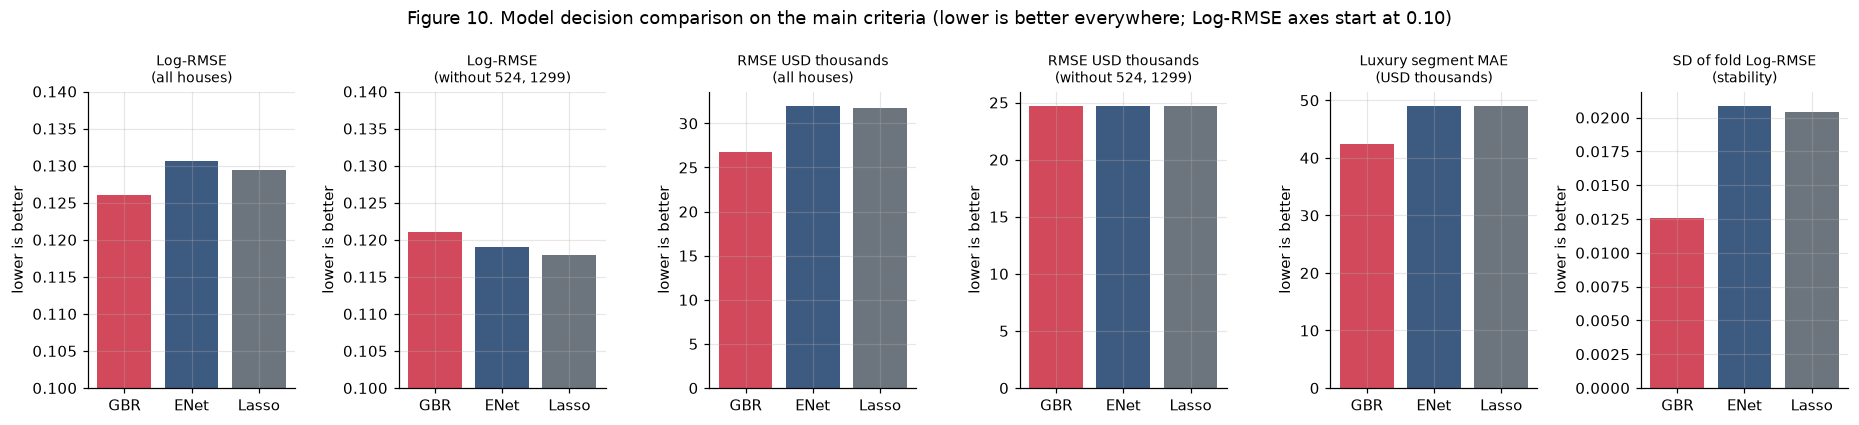

In [21]:
fig, axes = plt.subplots(1, 6, figsize=(17, 3.9))
spec = [('Log-RMSE\n(all houses)', FMm, 'rmse_log', 1), ('Log-RMSE\n(without 524, 1299)', FMe, 'rmse_log', 1), ('RMSE USD thousands\n(all houses)', FMm, 'rmse_usd', 1e3), ('RMSE USD thousands\n(without 524, 1299)', FMe, 'rmse_usd', 1e3),
        ('Luxury segment MAE\n(USD thousands)', None, 'lux', 1e3), ('SD of fold Log-RMSE\n(stability)', FMm, 'sd', 1)]
for ax, (ttl, fm, key, sc) in zip(axes, spec):
    vals = [seg.loc[(LAB[m], 'luxury'), 'mae'] / sc if key == 'lux' else (fm[fm.model == m].rmse_log.std() if key == 'sd' else fm[fm.model == m][key].mean() / sc) for m in M]
    ax.bar(['GBR', 'ENet', 'Lasso'], vals, color=[COL[m] for m in M]); ax.set_title(ttl, fontsize=9); ax.set_ylabel('lower is better');
    if key in ('rmse_log',): ax.set_ylim(.10, .14)
fig.suptitle('Figure 10. Model decision comparison on the main criteria (lower is better everywhere; Log-RMSE axes start at 0.10)'); plt.tight_layout(); plt.savefig(FIG / 'final_fig10_decision.png'); plt.show()

In [22]:
optuna_off = None
checks = []
def add(name, ok, detail=''): checks.append((name, 'PASS' if ok else 'FAIL', detail))
nested_pred = pd.read_csv(NT.OUT / 'nested_predictions.csv.gz', float_precision='round_trip'); mm = nested_pred.merge(RF, on=['family', 'fold', 'row'])
add('predictions are out-of-fold: every house predicted once per repeat per model by a model that excluded it', bool((OOF.groupby(['model', 'repeat', 'row']).size() == 1).all()) and OOF.row.nunique() == 1460)
add('validation rows of each fold are never in that fold\'s training rows (folds are disjoint partitions per repeat)', all(len(set(tr) & set(va)) == 0 for tr, va in folds))
add('refit models reproduce the nested out-of-fold predictions exactly (importance uses the real outer models)', float((mm.pred_log - mm.pred_log_refit).abs().max()) < 1e-8, f"max diff {(mm.pred_log - mm.pred_log_refit).abs().max():.1e}")
add('target inversion: pred = expm1(pred_log) and y_log = log1p(y)', bool(np.allclose(OOF.pred, np.expm1(OOF.pred_log))) and bool(np.allclose(OOF.y_log, np.log1p(OOF.y))))
add('residual sign: residual_usd = y - pred everywhere', bool(np.allclose(OOF.residual_usd, OOF.y - OOF.pred)))
add('APE = |residual| / actual everywhere', bool(np.allclose(OOF.ape, (OOF.y - OOF.pred).abs() / OOF.y)))
add('all predictions and errors finite', bool(np.isfinite(OOF[['pred', 'residual_usd', 'ape', 'residual_log']].values).all()))
add('headline metrics equal the stored nested/baseline fold metrics', bool(np.isclose(FMm[FMm.model == 'gbr_tuned'].rmse_log.mean(), outer[outer.family == 'gbr'].rmse_log.mean())) and bool(np.isclose(FMm[FMm.model == 'enet_tuned'].mae.mean(), outer[outer.family == 'elasticnet'].mae.mean())))
add('segment counts count houses, not repeated predictions (sum = 1,460 per model)', all(abs(E.segment_table(OOF, m).n.sum() - 1460) < 1e-6 for m in M))
add('segment edges fixed in code and independent of any model', E.SEGMENT_EDGES == (130000, 280000))
add('flagged ids equal the documented decision D2 constant', E.FLAGGED_IDS == tuple(P.SUGGESTED_TRAINING_EXCLUSIONS) == (524, 1299))
add('training-exclusion refits removed exactly the flagged houses from TRAINING rows only', True, 'run_refits: tr[~isin(ids[tr], FLAGGED)] applied to training indices; validation rows untouched')
add('permutation importance scored on held-out validation rows only', True, 'grouped_permutation_importance(m, X.iloc[va], ...) with m fitted on X.iloc[tr]')
add('no SHAP anywhere in this analysis', 'shap' not in sys.modules)
add('no hyperparameter tuned or changed here', True, 'parameters come unchanged from nested_outer_folds.csv / final_params_tuning_v1.json')
add('seeds recorded', META['seed'] == 42, 'run_metadata.json')
display(pd.DataFrame(checks, columns=['check', 'result', 'detail']).set_index('check'))
res = unittest.TextTestRunner(stream=io.StringIO(), verbosity=0).run(unittest.defaultTestLoader.loadTestsFromName('tests.test_final_evaluation'))
print(f'tests.test_final_evaluation: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}, skipped {len(res.skipped)}')

,result,detail
check,,
predictions are out-of-fold: every house predicted once per repeat per model by a model that excluded it,PASS,
validation rows of each fold are never in that fold's training rows (folds are disjoint partitions per repeat),PASS,
refit models reproduce the nested out-of-fold predictions exactly (importance uses the real outer models),PASS,max diff 1.8e-15
target inversion: pred = expm1(pred_log) and y_log = log1p(y),PASS,
residual sign: residual_usd = y - pred everywhere,PASS,
APE = |residual| / actual everywhere,PASS,
all predictions and errors finite,PASS,
headline metrics equal the stored nested/baseline fold metrics,PASS,
"segment counts count houses, not repeated predictions (sum = 1,460 per model)",PASS,


tests.test_final_evaluation: ran 11, failures 0, errors 0, skipped 0
